<a href="https://colab.research.google.com/github/laurenkahn7/fmri-language-localizer/blob/main/fmri_language_localizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nilearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 16.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 28.3 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [nilearn]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from nilearn.datasets import fetch_language_localizer_demo_dataset

data = fetch_language_localizer_demo_dataset()

print(data.data_dir)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


[fetch_language_localizer_demo_dataset] Added README.md to /root/nilearn_data

[fetch_language_localizer_demo_dataset] Dataset created in /root/nilearn_data/fMRI-language-localizer-demo-dataset

[fetch_language_localizer_demo_dataset] Downloading data from https://osf.io/nh987/download ...

[fetch_language_localizer_demo_dataset] Downloaded 10493952 of 749503182 bytes (1.4%%, 00 HR 01 MIN 14 SEC remaining)

[fetch_language_localizer_demo_dataset] Downloaded 31465472 of 749503182 bytes (4.2%%, 00 HR 00 MIN 50 SEC remaining)

... (33 outputs left out)

[fetch_language_localizer_demo_dataset]  ...done. (40 seconds, 0 min)

[fetch_language_localizer_demo_dataset] Extracting data from /root/nilearn_data/fMRI-language-localizer-demo-dataset/fMRI-language-localizer-demo-dataset.zip...

[fetch_language_localizer_demo_dataset] .. done.

/root/nilearn_data/fMRI-language-localizer-demo-dataset


In [3]:
from pathlib import Path

folder = Path(data.data_dir)

print("TOP LEVEL:")
for item in sorted(folder.iterdir()):
  print(" ",item.name)

print()
print("FILES FOR PERSON sub-01 (raw):")
for item in sorted(folder.glob("sub-01/**/*")):
  print(" ",item.relative_to(folder))

print()
print("FILES FOR PERSON sub-01(derivatives):")
for item in sorted(folder.glob("derivatives/sub-01/**/*")):
  print(" ",item.relative_to(folder))

TOP LEVEL:
  .bidsignore
  CHANGES
  README
  access_data.py
  dataset_description.json
  derivatives
  participants.tsv
  sub-01
  sub-02
  sub-03
  sub-04
  sub-05
  sub-06
  sub-07
  sub-08
  sub-09
  sub-10

FILES FOR PERSON sub-01 (raw):
  sub-01/func
  sub-01/func/sub-01_task-languagelocalizer_events.tsv

FILES FOR PERSON sub-01(derivatives):
  derivatives/sub-01/func
  derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-confounds_regressors.tsv
  derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-preproc_bold.json
  derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-preproc_bold.nii.gz


In [4]:
from pathlib import Path

print("Folder I'm looking in:", folder)
print("Does it exist?", Path(folder).exists())
print()
print("Files that end in events.tsv:")
for f in sorted(Path(folder).rglob("*events.tsv"))[:5]:
    print("  ", f)
print()
print("Everything at the top level:")
for item in sorted(Path(folder).iterdir()):
    print("  ", item.name)

Folder I'm looking in: /root/nilearn_data/fMRI-language-localizer-demo-dataset
Does it exist? True

Files that end in events.tsv:
   /root/nilearn_data/fMRI-language-localizer-demo-dataset/sub-01/func/sub-01_task-languagelocalizer_events.tsv
   /root/nilearn_data/fMRI-language-localizer-demo-dataset/sub-02/func/sub-02_task-languagelocalizer_events.tsv
   /root/nilearn_data/fMRI-language-localizer-demo-dataset/sub-03/func/sub-03_task-languagelocalizer_events.tsv
   /root/nilearn_data/fMRI-language-localizer-demo-dataset/sub-04/func/sub-04_task-languagelocalizer_events.tsv
   /root/nilearn_data/fMRI-language-localizer-demo-dataset/sub-05/func/sub-05_task-languagelocalizer_events.tsv

Everything at the top level:
   .bidsignore
   CHANGES
   README
   access_data.py
   dataset_description.json
   derivatives
   participants.tsv
   sub-01
   sub-02
   sub-03
   sub-04
   sub-05
   sub-06
   sub-07
   sub-08
   sub-09
   sub-10


In [5]:
from pathlib import Path

inner = Path("/root/nilearn_data/fMRI-language-localizer-demo-dataset")
all_items = list(inner.rglob("*"))
print("Total items inside:", len(all_items))
for item in sorted(all_items)[:15]:
    print("  ", item.relative_to(inner))

Total items inside: 88
   .bidsignore
   CHANGES
   README
   access_data.py
   dataset_description.json
   derivatives
   derivatives/dataset_description.json
   derivatives/sub-01
   derivatives/sub-01/func
   derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-confounds_regressors.tsv
   derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-preproc_bold.json
   derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-preproc_bold.nii.gz
   derivatives/sub-02
   derivatives/sub-02/func
   derivatives/sub-02/func/sub-02_task-languagelocalizer_desc-confounds_regressors.tsv


In [6]:
from nilearn.datasets import fetch_language_localizer_demo_dataset

data = fetch_language_localizer_demo_dataset()
print(data.data_dir)

[fetch_language_localizer_demo_dataset] Dataset directory found: /root/nilearn_data/fMRI-language-localizer-demo-dataset

/root/nilearn_data/fMRI-language-localizer-demo-dataset


In [7]:
!curl -L -I https://osf.io/nh987/download

HTTP/1.1 301 Moved Permanently
Date: Thu, 05 Nov 2026 02:32:30 GMT
Content-Type: text/html
Content-Length: 162
Connection: keep-alive
Location: ]8;;https://osf.io/download/nh987\https://osf.io/download/nh987
]8;;\Strict-Transport-Security: max-age=31536000
X-Frame-Options: SAMEORIGIN
X-Content-Type-Options: nosniff
Referrer-Policy: strict-origin
Permissions-Policy: camera=(), microphone=(), geolocation=(), payment=(), usb=(), bluetooth=()

HTTP/1.1 308 PERMANENT REDIRECT
Date: Thu, 05 Nov 2026 02:32:30 GMT
Content-Type: text/html; charset=utf-8
Content-Length: 247
Connection: keep-alive
Location: ]8;;https://osf.io/download/nh987/\https://osf.io/download/nh987/
]8;;\Access-Control-Allow-Origin: https://osf.io
Access-Control-Allow-Credentials: true
X-Frame-Options: SAMEORIGIN
X-Cache-Status: MISS
Cache-Control: no-cache, no-store, max-age=0, must-revalidate
Expires: -1
Pragma: no-cache

HTTP/1.1 302 FOUND
Date: Thu, 05 Nov 2026 02:32:31 GMT
Content-Type: text/html; charset=utf-8

In [8]:
!curl -L -s -o /content/lang.zip -w "final status: %{http_code}  size: %{size_download} bytes\n" https://osf.io/nh987/download
!ls -la /content/lang.zip

final status: 200  size: 749503182 bytes
-rw-r--r-- 1 root root 749503182 Nov  5 02:33 /content/lang.zip


In [9]:
!unzip -q -o /content/lang.zip -d /content/language_localizer

from pathlib import Path

found = sorted(Path("/content/language_localizer").rglob("sub-01"))
print("Folders named sub-01:")
for f in found:
    print("  ", f)

Folders named sub-01:
   /content/language_localizer/derivatives/sub-01
   /content/language_localizer/sub-01


In [10]:
from pathlib import Path

folder = Path("/content/language_localizer")

print("TOP LEVEL:")
for item in sorted(folder.iterdir()):
    print("  ", item.name)

TOP LEVEL:
   .bidsignore
   CHANGES
   README
   access_data.py
   dataset_description.json
   derivatives
   participants.tsv
   sub-01
   sub-02
   sub-03
   sub-04
   sub-05
   sub-06
   sub-07
   sub-08
   sub-09
   sub-10


In [11]:
import pandas as pd

events_file = next(folder.glob("sub-01/func/*events.tsv"))
events = pd.read_csv(events_file, sep="\t")

print(events)
print()
print(events["trial_type"].value_counts())

      onset  duration trial_type
0     3.516     6.806   language
1    17.707     7.004     string
2    32.011     6.805   language
3    46.306     7.206     string
4    60.604     6.804   language
5    74.908     6.804     string
6    89.208     6.808   language
7   103.508     6.806     string
8   117.804     6.806   language
9   132.108     6.809     string
10  146.407     6.805   language
11  160.702     6.807     string
12  175.007     6.804   language
13  189.304     6.805     string
14  203.608     6.802   language
15  217.910     6.806     string
16  232.206     6.809   language
17  246.504     6.802     string
18  260.807     6.800   language
19  275.109     6.806     string
20  289.406     6.806   language
21  303.703     6.803     string
22  318.007     6.807   language
23  332.305     6.810     string

trial_type
language    12
string      12
Name: count, dtype: int64


shape: (45, 53, 43, 229)
Voxel sizes and time step: (np.float32(4.5), np.float32(4.5), np.float32(4.5), np.float32(1.5))


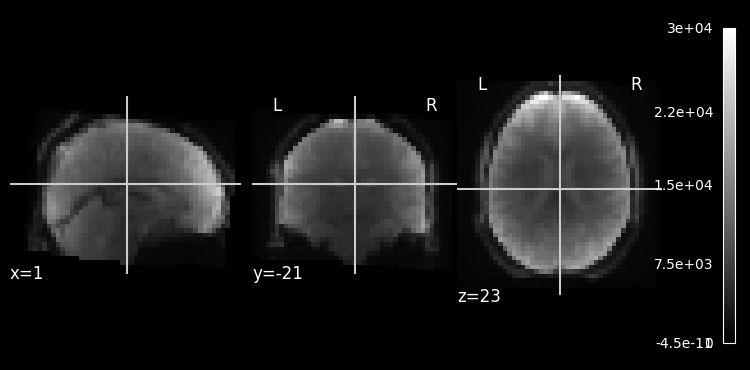

In [12]:
from nilearn.image import load_img, mean_img
from nilearn.plotting import plot_epi

scan_file = next(folder.glob("derivatives/sub-01/func/*preproc_bold.nii.gz"))
scan = load_img(scan_file)

print("shape:",scan.shape)
print("Voxel sizes and time step:", scan.header.get_zooms())

plot_epi(mean_img(scan))

In [13]:
tr = scan.header.get_zooms()[3]
n_pictures = scan.shape[3]

print("Seconds between brain pictures (TR):", tr)
print("Number of brain pictures:", n_pictures)
print("Total scan length (seconds):", n_pictures * tr)
print("Last block ends at (seconds):", (events["onset"] + events["duration"]).max())

Seconds between brain pictures (TR): 1.5
Number of brain pictures: 229
Total scan length (seconds): 343.5
Last block ends at (seconds): 339.115


In [14]:
!pip install -q nilearn

from pathlib import Path
import os

folder = Path("/content/language_localizer")

if not (folder / "sub-01").exists():
    print("Data missing, downloading (about 750 MB, 1-2 minutes)...")
    !curl -L -s -o /content/lang.zip https://osf.io/nh987/download
    !unzip -q -o /content/lang.zip -d /content/language_localizer
else:
    print("Data already there, skipping download.")

print("Subjects found:", sorted(p.name for p in folder.glob("sub-*")))

Data already there, skipping download.
Subjects found: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10']


In [15]:
from nilearn.glm.first_level import first_level_from_bids

task_label = "languagelocalizer"
models, models_run_imgs, models_events, models_confounds = first_level_from_bids(
    str(folder),
    task_label,
    img_filters=[("desc", "preproc")],
    n_jobs=2,
    space_label="",
    smoothing_fwhm=8,

)
print("Number of models (people):", len(models))
print("Subject labels:", [m.subject_label for m in models])
print("Confound columns:", list(models_confounds[0][0].columns))

/tmp/ipykernel_1458/3159942532.py:4: RuntimeWarning: 'StartTime' not found in file /content/language_localizer/derivatives/sub-01/func/sub-01_task-languagelocalizer_desc-preproc_bold.json.
  models, models_run_imgs, models_events, models_confounds = first_level_from_bids(
/tmp/ipykernel_1458/3159942532.py:4: UserWarning: 'slice_time_ref' not provided and cannot be inferred from metadata.
It will be assumed that the slice timing reference is 0.0 percent of the repetition time.
If it is not the case it will need to be set manually in the generated list of models.
  models, models_run_imgs, models_events, models_confounds = first_level_from_bids(


Number of models (people): 10
Subject labels: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10']
Confound columns: ['RotX', 'RotY', 'RotZ', 'X', 'Y', 'Z']


In [16]:
from scipy.stats import norm
from nilearn import plotting

p001_unc = norm.isf(0.001)

z_maps = []
for model, imgs, ev, conf in zip(models, models_run_imgs, models_events, models_confounds):
  model.fit(imgs, events=ev, confounds=conf)
  z_maps.append(model.compute_contrast("language-string"))
  print("finished person", model.subject_label)



finished person 01
finished person 02
finished person 03
finished person 04
finished person 05
finished person 06
finished person 07
finished person 08
finished person 09
finished person 10


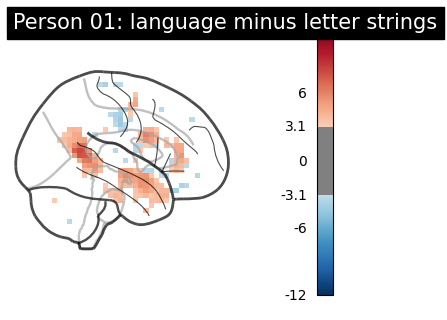

In [17]:
plotting.plot_glass_brain(
    z_maps[0],
    threshold=p001_unc,
    plot_abs=False,
    display_mode="x",
    vmin=-12,
    vmax=12,
    title="Person 01: language minus letter strings",
)

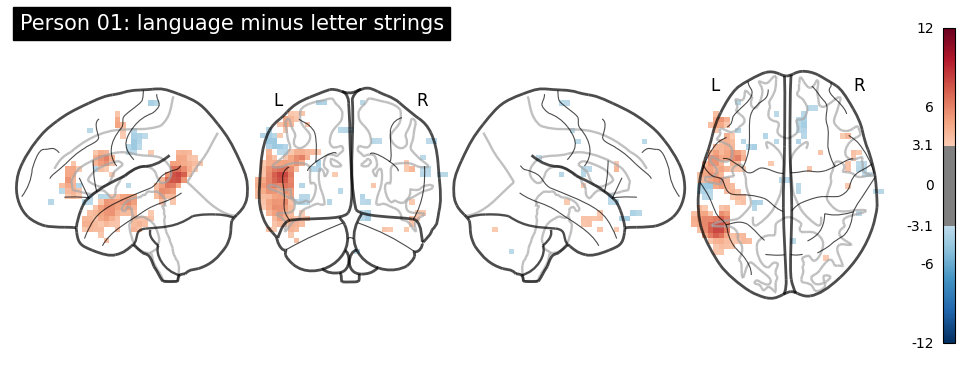

In [18]:
plotting.plot_glass_brain(
    z_maps[0],
    threshold=p001_unc,
    plot_abs=False,
    display_mode="lyrz",
    vmin=-12,
    vmax=12,
    title="Person 01: language minus letter strings",
)

Saved group_language_map.png


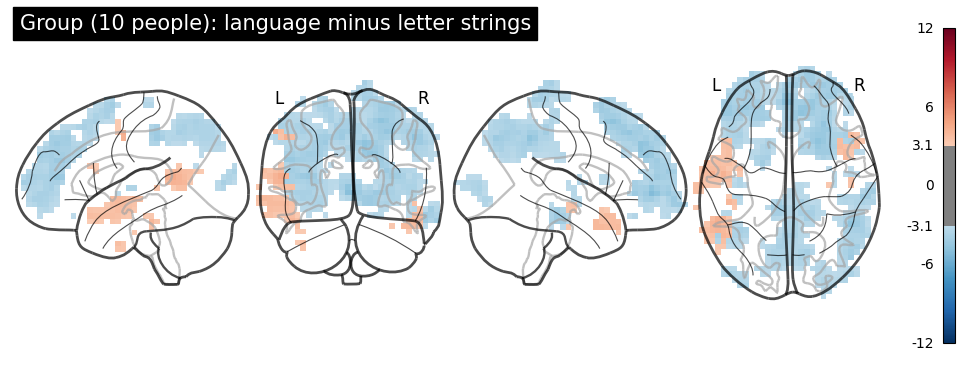

In [19]:
from nilearn.glm.second_level import SecondLevelModel

second_level = SecondLevelModel(smoothing_fwhm=8.0, n_jobs=2)
second_level = second_level.fit(models)

group_zmap = second_level.compute_contrast(
    first_level_contrast="language-string",
    output_type="z_score",
)

plotting.plot_glass_brain(
    group_zmap,
    threshold=p001_unc,
    plot_abs=False,
    display_mode="lyrz",
    vmin=-12,
    vmax=12,
    title="Group (10 people): language minus letter strings",
    output_file="group_language_map.png"

    )
print("Saved group_language_map.png")

In [20]:
import numpy as np

z = group_zmap.get_fdata()
spots = np.argwhere(z > p001_unc)
x_positions = (group_zmap.affine @ np.c_[spots, np.ones(len(spots))].T)[0]

left = (x_positions < 0).sum()
right = (x_positions > 0).sum()

print("Red voxels in LEFT hemisphere:", left)
print("Red voxels in RIGHT hemisphere", right)
print("Left share of all red voxels:", round(left / (left + right) * 100, 1), "%")

Red voxels in LEFT hemisphere: 213
Red voxels in RIGHT hemisphere 42
Left share of all red voxels: 83.5 %
